# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Ayubi Fathan
- **Email:** ds001b6y0302@student.devacademy.id
- **ID Dicoding:** ds001b6y0302

## Menentukan Pertanyaan Bisnis

Proyek analisis data ini bertujuan untuk menjawab dua pertanyaan bisnis utama yang disusun menggunakan kerangka kerja **SMART** (Specific, Measurable, Action-oriented, Relevant, Time-bound):

1. **Pertanyaan 1 (Performa Produk & Penjualan):**
   *Kategori produk apa saja yang mencatatkan volume penjualan (jumlah item terjual) dan pendapatan (*revenue*) tertinggi serta terendah sepanjang tahun 2017–2018?*
   - **Specific:** Fokus pada performa volume item dan total nilai transaksi (pendapatan) per kategori produk secara menyeluruh.
   - **Measurable:** Diukur secara konkret dengan metrik total order items yang terjual dan total revenue (dalam Brazilian Real / BRL).
   - **Action-Oriented:** Memberikan acuan kuantitatif untuk pengelolaan inventaris, alokasi stok pengaman (*safety stock*), dan strategi evaluasi kategori produk berkinerja rendah.
   - **Relevant:** Mengoptimalkan portofolio produk e-commerce guna memaksimalkan profitabilitas platform.
   - **Time-bound:** Dibatasi pada periode transaksi penuh 2017 hingga 2018.

2. **Pertanyaan 2 (Kepuasan Pelanggan & Logistik):**
   *Bagaimana korelasi dan perbedaan rata-rata skor ulasan (*customer review score*) antara pesanan tepat waktu (*On Time*) dan pesanan terlambat (*Late*) pada transaksi tahun 2017–2018?*
   - **Specific:** Mengukur hubungan statistik antara ketepatan waktu pengiriman aktual terhadap skor ulasan (skala 1–5).
   - **Measurable:** Dihitung dari perbandingan rata-rata *review score*, persentase penurunan skor, serta koefisien korelasi statistik antara keterlambatan dengan skor ulasan.
   - **Action-Oriented:** Menjadi dasar peninjauan Service Level Agreement (SLA) mitra logistik dan penerapan estimasi waktu pengiriman yang lebih dinamis.
   - **Relevant:** Kepuasan dan retensi pelanggan merupakan indikator kesehatan utama bisnis retail e-commerce.
   - **Time-bound:** Transaksi pada rentang waktu 2017 hingga 2018.

## Menyiapkan semua library yang dibutuhkan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import folium
from folium.plugins import HeatMap
import os

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True
print("Semua library berhasil dimuat dengan sukses.")

Semua library berhasil dimuat dengan sukses.


## Data Wrangling

### Gathering Data
Memuat seluruh dataset CSV yang diperlukan ke dalam DataFrame Pandas. Dataset meliputi tabel pesanan (*orders*), item pesanan (*order_items*), ulasan (*order_reviews*), pembayaran (*order_payments*), pelanggan (*customers*), produk (*products*), penjual (*sellers*), data geolokasi (*geolocation*), dan terjemahan kategori (*product_category_name_translation*).

In [2]:
# Memuat data
data_dir = "data"
orders_df = pd.read_csv(os.path.join(data_dir, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(data_dir, "order_items_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(data_dir, "order_reviews_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(data_dir, "order_payments_dataset.csv"))
customers_df = pd.read_csv(os.path.join(data_dir, "customers_dataset.csv"))
products_df = pd.read_csv(os.path.join(data_dir, "products_dataset.csv"))
sellers_df = pd.read_csv(os.path.join(data_dir, "sellers_dataset.csv"))
geolocation_df = pd.read_csv(os.path.join(data_dir, "geolocation_dataset.csv"))
category_trans_df = pd.read_csv(os.path.join(data_dir, "product_category_name_translation.csv"))

print(f"Jumlah baris orders_df: {orders_df.shape[0]:,}")
print(f"Jumlah baris order_items_df: {order_items_df.shape[0]:,}")
print(f"Jumlah baris order_reviews_df: {order_reviews_df.shape[0]:,}")
print(f"Jumlah baris order_payments_df: {order_payments_df.shape[0]:,}")
print(f"Jumlah baris customers_df: {customers_df.shape[0]:,}")
print(f"Jumlah baris products_df: {products_df.shape[0]:,}")
print(f"Jumlah baris sellers_df: {sellers_df.shape[0]:,}")
print(f"Jumlah baris geolocation_df: {geolocation_df.shape[0]:,}")

Jumlah baris orders_df: 99,441
Jumlah baris order_items_df: 112,650
Jumlah baris order_reviews_df: 99,224
Jumlah baris order_payments_df: 103,886
Jumlah baris customers_df: 99,441
Jumlah baris products_df: 32,951
Jumlah baris sellers_df: 3,095
Jumlah baris geolocation_df: 1,000,163


### Assessing Data
Memeriksa integritas data: nilai hilang (*missing values*), tipe data yang tidak sesuai, duplikasi, dan inkonsistensi nilai.

In [3]:
# Pemeriksaan tipe data dan missing value orders_df
print("--- Orders Info ---")
orders_df.info()
print()
print("Missing values in orders_df:")
print(orders_df.isna().sum())

--- Orders Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values in orders_df:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrie

In [4]:
# Pemeriksaan missing values dan duplikasi pada tabel lain
print("Missing values in products_df:")
print(products_df.isna().sum())
print()
print("Missing values in order_reviews_df:")
print(order_reviews_df.isna().sum())
print()
print("Duplikasi data:")
print("orders_df duplicates:", orders_df.duplicated().sum())
print("customers_df duplicates:", customers_df.duplicated().sum())
print("products_df duplicates:", products_df.duplicated().sum())
print("sellers_df duplicates:", sellers_df.duplicated().sum())

Missing values in products_df:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Missing values in order_reviews_df:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplikasi data:


orders_df duplicates: 0
customers_df duplicates: 0
products_df duplicates: 0
sellers_df duplicates: 0


**Temuan Assessing Data:**
1. **Tipe Data Tanggal:** Kolom tanggal pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) bertipe `object` (string), sehingga harus diubah ke format `datetime`.
2. **Missing Values pada Pengiriman:** Terdapat 2.965 baris nilai hilang pada `order_delivered_customer_date` karena pesanan belum selesai atau dibatalkan (*canceled/unavailable*).
3. **Missing Values pada Produk:** Kolom `product_category_name` memiliki 610 nilai hilang yang perlu diisi kategori standar (`others`) agar tidak mengganggu agregasi kategori.
4. **Bahasa Kategori:** Nama kategori produk pada `products_df` menggunakan bahasa Portugis, sehingga digabungkan dengan `product_category_name_translation.csv` untuk menghasilkan nama kategori berbahasa Inggris.
5. **Outlier dan Redundansi Geolokasi:** Dataset `geolocation_df` memiliki lebih dari 1 juta baris dengan redundansi kode pos serta beberapa koordinat di luar batas geografis Brasil (koordinat latitude valid Brasil: -33.75 hingga 5.27, longitude: -73.98 hingga -34.79).

### Cleaning Data
Tindakan pembersihan yang dilakukan:
1. Mengonversi seluruh kolom tanggal pada `orders_df` ke tipe `datetime64[ns]`.
2. Melakukan translasi nama kategori produk ke bahasa Inggris dan mengisi nilai hilang dengan `'others'`.
3. Memfilter pesanan berstatus `'delivered'` dengan tanggal kedatangan pelanggan yang valid untuk analisis kepuasan dan performa logistik.
4. Membuat kolom metrik pengiriman:
   - `delivery_time_days`: durasi waktu tempuh pesanan dari pembelian hingga sampai ke tangan pelanggan (dalam hari).
   - `delivery_delay_days`: selisih waktu antara kedatangan aktual dengan estimasi tanggal kirim.
   - `delivery_status`: `'Late'` jika `delivery_delay_days > 0`, selain itu `'On Time'`.
   - `is_late`: dummy variabel biner (1 untuk Late, 0 untuk On Time).
5. Membersihkan data geolokasi Brasil dan mengagregasi koordinat rata-rata (mean latitude & longitude) per kode pos (*zip code prefix*) agar bersih dari duplikasi dan outlier.
6. Menggabungkan tabel terkait menjadi satu DataFrame bersih terpadu.

In [5]:
# 1. Konversi kolom tanggal ke datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

# 2. Translasi nama kategori produk
products_clean_df = products_df.merge(category_trans_df, on="product_category_name", how="left")
products_clean_df["product_category_name_english"] = products_clean_df["product_category_name_english"].fillna("others")

# 3. Hitung fitur keterlambatan pengiriman
orders_clean_df = orders_df[
    (orders_df["order_status"] == "delivered") & 
    orders_df["order_delivered_customer_date"].notna()
].copy()

orders_clean_df["delivery_time_days"] = (orders_clean_df["order_delivered_customer_date"] - orders_clean_df["order_purchase_timestamp"]).dt.total_seconds() / 86400
orders_clean_df["delivery_delay_days"] = (orders_clean_df["order_delivered_customer_date"] - orders_clean_df["order_estimated_delivery_date"]).dt.total_seconds() / 86400
orders_clean_df["delivery_status"] = np.where(orders_clean_df["delivery_delay_days"] > 0, "Late", "On Time")
orders_clean_df["is_late"] = (orders_clean_df["delivery_status"] == "Late").astype(int)

# 4. Agregasi review score rata-rata per order
reviews_agg_df = order_reviews_df.groupby("order_id", as_index=False).agg({"review_score": "mean"})

# 5. Gabungkan menjadi DataFrame terpadu
merged_df = orders_clean_df.merge(customers_df[["customer_id", "customer_unique_id", "customer_state", "customer_city", "customer_zip_code_prefix"]], on="customer_id", how="inner")
merged_df = merged_df.merge(order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]], on="order_id", how="inner")
merged_df = merged_df.merge(products_clean_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
merged_df = merged_df.merge(reviews_agg_df, on="order_id", how="left")

# Fitur waktu tambahan
merged_df["order_year"] = merged_df["order_purchase_timestamp"].dt.year
merged_df["year_month"] = merged_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

# Isi review score jika ada NaN dengan median
merged_df["review_score"] = merged_df["review_score"].fillna(merged_df["review_score"].median())

# 6. Pembersihan data geolokasi (Batas wilayah Brasil)
geo_clean = geolocation_df[
    (geolocation_df["geolocation_lat"] <= 5.27) & (geolocation_df["geolocation_lat"] >= -33.75) & 
    (geolocation_df["geolocation_lng"] <= -34.79) & (geolocation_df["geolocation_lng"] >= -73.98)
].copy()

geo_agg_df = geo_clean.groupby("geolocation_zip_code_prefix").agg({
    "geolocation_lat": "mean",
    "geolocation_lng": "mean",
    "geolocation_city": "first",
    "geolocation_state": "first"
}).reset_index()

print(f"Data transaksi bersih siap dianalisis: {merged_df.shape[0]:,} baris, {merged_df.shape[1]} kolom.")
print(f"Data geolokasi unik teragregasi: {geo_agg_df.shape[0]:,} kode pos.")

Data transaksi bersih siap dianalisis: 110,189 baris, 24 kolom.
Data geolokasi unik teragregasi: 19,010 kode pos.


## Exploratory Data Analysis (EDA)

### Eksplorasi Pertanyaan 1: Performa Penjualan & Pendapatan (Revenue) Kategori Produk (2017–2018)
Kita memfilter transaksi pada periode tahun 2017 hingga 2018 untuk mengidentifikasi kategori produk dengan volume penjualan tertinggi dan terendah, serta pendapatan (*revenue*) tertinggi dan terendah.

In [6]:
# Filter transaksi tahun 2017 - 2018
df_2017_2018 = merged_df[merged_df["order_year"].isin([2017, 2018])]

# Agregasi performa kategori produk
category_performance = df_2017_2018.groupby("product_category_name_english").agg(
    total_items_sold=("order_item_id", "count"),
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum"),
    avg_price=("price", "mean")
).reset_index()

# 1. Top 5 berdasarkan Volume Penjualan (Jumlah Item Terjual)
top_5_volume = category_performance.sort_values(by="total_items_sold", ascending=False).head(5)
print("=== TOP 5 KATEGORI BERDASARKAN VOLUME PENJUALAN (JUMLAH ITEM) ===")
for _, row in top_5_volume.iterrows():
    print(f"- {row['product_category_name_english']}: {row['total_items_sold']:,} item | Revenue: R$ {row['total_revenue']:,.2f}")

# 2. Top 5 berdasarkan Pendapatan (Revenue)
top_5_revenue = category_performance.sort_values(by="total_revenue", ascending=False).head(5)
print("\n=== TOP 5 KATEGORI BERDASARKAN PENDAPATAN (TOTAL REVENUE) ===")
for _, row in top_5_revenue.iterrows():
    print(f"- {row['product_category_name_english']}: R$ {row['total_revenue']:,.2f} | Volume: {row['total_items_sold']:,} item")

# 3. Bottom 5 berdasarkan Volume Penjualan (Jumlah Item Terjual)
bottom_5_volume = category_performance.sort_values(by="total_items_sold", ascending=True).head(5)
print("\n=== BOTTOM 5 KATEGORI BERDASARKAN VOLUME PENJUALAN (JUMLAH ITEM) ===")
for _, row in bottom_5_volume.iterrows():
    print(f"- {row['product_category_name_english']}: {row['total_items_sold']:,} item | Revenue: R$ {row['total_revenue']:,.2f}")

# 4. Bottom 5 berdasarkan Pendapatan (Revenue)
bottom_5_revenue = category_performance.sort_values(by="total_revenue", ascending=True).head(5)
print("\n=== BOTTOM 5 KATEGORI BERDASARKAN PENDAPATAN (TOTAL REVENUE) ===")
for _, row in bottom_5_revenue.iterrows():
    print(f"- {row['product_category_name_english']}: R$ {row['total_revenue']:,.2f} | Volume: {row['total_items_sold']:,} item")

=== TOP 5 KATEGORI BERDASARKAN VOLUME PENJUALAN (JUMLAH ITEM) ===
- bed_bath_table: 10,945 item | Revenue: R$ 1,022,955.77
- health_beauty: 9,422 item | Revenue: R$ 1,229,557.50
- sports_leisure: 8,413 item | Revenue: R$ 952,661.40
- furniture_decor: 8,095 item | Revenue: R$ 706,237.17
- computers_accessories: 7,631 item | Revenue: R$ 887,944.60

=== TOP 5 KATEGORI BERDASARKAN PENDAPATAN (TOTAL REVENUE) ===
- health_beauty: R$ 1,229,557.50 | Volume: 9,422 item
- watches_gifts: R$ 1,163,187.91 | Volume: 5,853 item
- bed_bath_table: R$ 1,022,955.77 | Volume: 10,945 item
- sports_leisure: R$ 952,661.40 | Volume: 8,413 item
- computers_accessories: R$ 887,944.60 | Volume: 7,631 item

=== BOTTOM 5 KATEGORI BERDASARKAN VOLUME PENJUALAN (JUMLAH ITEM) ===
- security_and_services: 2 item | Revenue: R$ 283.29
- fashion_childrens_clothes: 7 item | Revenue: R$ 519.95
- la_cuisine: 14 item | Revenue: R$ 2,054.99
- cds_dvds_musicals: 14 item | Revenue: R$ 730.00
- arts_and_craftmanship: 24 item | Re

### Eksplorasi Pertanyaan 2: Korelasi Status Pengiriman terhadap Review Score
Kita menganalisis perbandingan rata-rata skor ulasan antara pesanan tepat waktu (*On Time*) dan terlambat (*Late*), menghitung persentase penurunan skor secara matematis, menguji signifikansi korelasi statistik, serta memeriksa jumlah transaksi sebagai konteks analisis.

In [7]:
# Ringkasan transaksi unik tingkat pesanan (order level)
order_level_2017_2018 = df_2017_2018.drop_duplicates(subset=["order_id"]).copy()

total_orders_count = len(order_level_2017_2018)
delivery_summary = order_level_2017_2018.groupby("delivery_status").agg(
    total_orders=("order_id", "count"),
    avg_review_score=("review_score", "mean"),
    std_review_score=("review_score", "std"),
    median_review_score=("review_score", "median")
).reset_index()

delivery_summary["percentage_orders"] = (delivery_summary["total_orders"] / total_orders_count) * 100

print(f"Total Pesanan Transaksi (2017-2018): {total_orders_count:,} pesanan")
print("=== PERBANDINGAN TRANSAKSI TEPAT WAKTU VS TERLAMBAT ===")
for _, row in delivery_summary.iterrows():
    print(f"- Status {row['delivery_status']}: {row['total_orders']:,} pesanan ({row['percentage_orders']:.2f}%) | "
          f"Rata-rata Skor: {row['avg_review_score']:.2f} (Std: {row['std_review_score']:.2f})")

# Perhitungan persentase penurunan skor
score_ontime = delivery_summary.loc[delivery_summary["delivery_status"] == "On Time", "avg_review_score"].values[0]
score_late = delivery_summary.loc[delivery_summary["delivery_status"] == "Late", "avg_review_score"].values[0]
score_diff = score_ontime - score_late
score_drop_pct = (score_diff / score_ontime) * 100

print(f"\nDasar Perhitungan Penurunan Skor:")
print(f"Selisih Penurunan = {score_ontime:.4f} - {score_late:.4f} = {score_diff:.4f} poin")
print(f"Persentase Penurunan = ({score_diff:.4f} / {score_ontime:.4f}) * 100% = {score_drop_pct:.2f}%")

# Pengukuran Korelasi Statistik (Pearson & Spearman)
r_late, p_late = stats.pearsonr(order_level_2017_2018["is_late"], order_level_2017_2018["review_score"])
r_delay, p_delay = stats.pearsonr(order_level_2017_2018["delivery_delay_days"], order_level_2017_2018["review_score"])
rho_delay, p_rho = stats.spearmanr(order_level_2017_2018["delivery_delay_days"], order_level_2017_2018["review_score"])

print("\n=== HASIL PENGUKURAN KORELASI STATISTIK ===")
print(f"- Pearson r (Keterlambatan Biner 'is_late' vs 'review_score'): r = {r_late:.4f} (p-value = {p_late:.4e})")
print(f"- Pearson r (Durasi Keterlambatan 'delay_days' vs 'review_score'): r = {r_delay:.4f} (p-value = {p_delay:.4e})")
print(f"- Spearman rho ('delay_days' vs 'review_score'): rho = {rho_delay:.4f} (p-value = {p_rho:.4e})")

# Distribusi rating 1-5 berdasarkan status pengiriman
rating_dist = pd.crosstab(
    order_level_2017_2018["delivery_status"], 
    order_level_2017_2018["review_score"].round().astype(int), 
    normalize="index"
) * 100
print("\n=== DISTRIBUSI PERSENTASE SKOR ULASAN (%) ===")
print(rating_dist.round(2))

Total Pesanan Transaksi (2017-2018): 96,203 pesanan
=== PERBANDINGAN TRANSAKSI TEPAT WAKTU VS TERLAMBAT ===
- Status Late: 7,822 pesanan (8.13%) | Rata-rata Skor: 2.62 (Std: 1.68)
- Status On Time: 88,381 pesanan (91.87%) | Rata-rata Skor: 4.30 (Std: 1.14)

Dasar Perhitungan Penurunan Skor:
Selisih Penurunan = 4.2989 - 2.6177 = 1.6812 poin
Persentase Penurunan = (1.6812 / 4.2989) * 100% = 39.11%

=== HASIL PENGUKURAN KORELASI STATISTIK ===
- Pearson r (Keterlambatan Biner 'is_late' vs 'review_score'): r = -0.3588 (p-value = 0.0000e+00)
- Pearson r (Durasi Keterlambatan 'delay_days' vs 'review_score'): r = -0.2643 (p-value = 0.0000e+00)
- Spearman rho ('delay_days' vs 'review_score'): rho = -0.1735 (p-value = 0.0000e+00)



=== DISTRIBUSI PERSENTASE SKOR ULASAN (%) ===
review_score         1     2      3      4      5
delivery_status                                  
Late             45.14  7.79  11.10  12.13  23.84
On Time           6.50  2.65   7.95  20.30  62.60


## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang memiliki volume penjualan dan pendapatan (revenue) tertinggi serta terendah sepanjang tahun 2017–2018?

C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\1216258291.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\1216258291.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\1216258291.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\1216258291.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hu

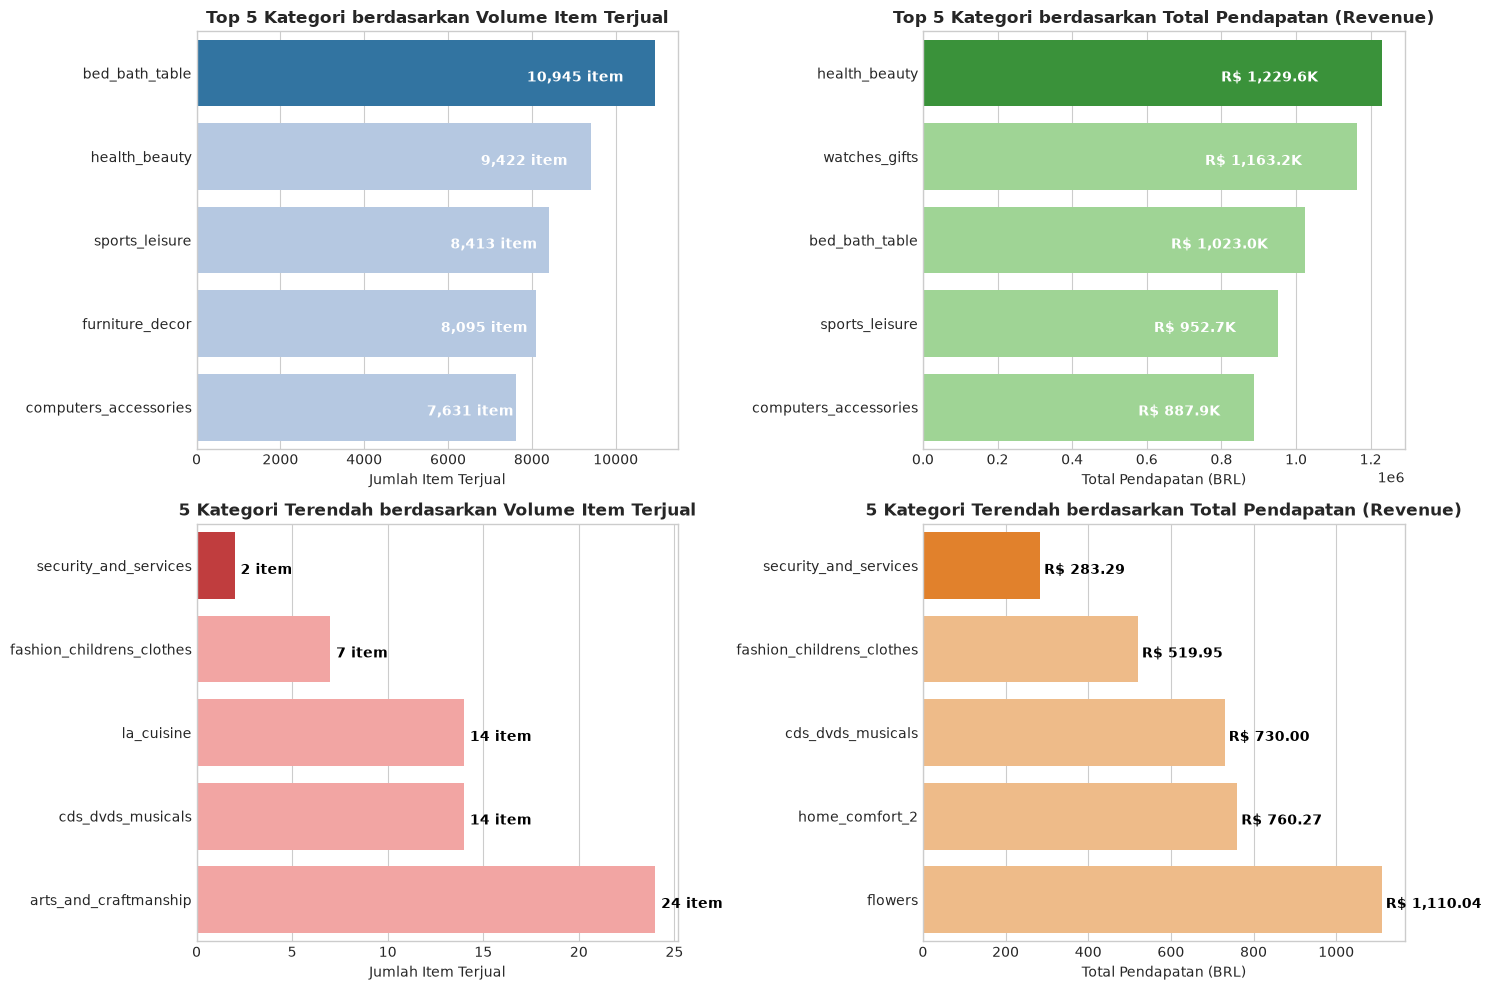

In [8]:
# Visualisasi Komprehensif: Top & Bottom berdasarkan Volume Item vs Revenue
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

# 1. Top 5 Kategori Penjualan (Volume Item)
sns.barplot(
    x="total_items_sold", 
    y="product_category_name_english", 
    data=top_5_volume, 
    palette=["#1f77b4" if i==0 else "#aec7e8" for i in range(5)],
    ax=axes[0, 0]
)
axes[0, 0].set_title("Top 5 Kategori berdasarkan Volume Item Terjual", fontsize=12, weight="bold")
axes[0, 0].set_xlabel("Jumlah Item Terjual", fontsize=10)
axes[0, 0].set_ylabel("")
for p in axes[0, 0].patches:
    val = int(p.get_width())
    axes[0, 0].annotate(f"{val:,} item", (val * 0.72, p.get_y() + 0.5), color="white", weight="bold")

# 2. Top 5 Kategori berdasarkan Total Pendapatan (Revenue)
sns.barplot(
    x="total_revenue", 
    y="product_category_name_english", 
    data=top_5_revenue, 
    palette=["#2ca02c" if i==0 else "#98df8a" for i in range(5)],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top 5 Kategori berdasarkan Total Pendapatan (Revenue)", fontsize=12, weight="bold")
axes[0, 1].set_xlabel("Total Pendapatan (BRL)", fontsize=10)
axes[0, 1].set_ylabel("")
for p in axes[0, 1].patches:
    val = p.get_width()
    axes[0, 1].annotate(f"R$ {val/1e3:,.1f}K", (val * 0.65, p.get_y() + 0.5), color="white", weight="bold")

# 3. Bottom 5 Kategori Penjualan (Volume Item)
sns.barplot(
    x="total_items_sold", 
    y="product_category_name_english", 
    data=bottom_5_volume, 
    palette=["#d62728" if i==0 else "#ff9896" for i in range(5)],
    ax=axes[1, 0]
)
axes[1, 0].set_title("5 Kategori Terendah berdasarkan Volume Item Terjual", fontsize=12, weight="bold")
axes[1, 0].set_xlabel("Jumlah Item Terjual", fontsize=10)
axes[1, 0].set_ylabel("")
for p in axes[1, 0].patches:
    val = int(p.get_width())
    axes[1, 0].annotate(f"{val:,} item", (val + 0.3, p.get_y() + 0.5), color="black", weight="bold")

# 4. Bottom 5 Kategori berdasarkan Total Pendapatan (Revenue)
sns.barplot(
    x="total_revenue", 
    y="product_category_name_english", 
    data=bottom_5_revenue, 
    palette=["#ff7f0e" if i==0 else "#ffbb78" for i in range(5)],
    ax=axes[1, 1]
)
axes[1, 1].set_title("5 Kategori Terendah berdasarkan Total Pendapatan (Revenue)", fontsize=12, weight="bold")
axes[1, 1].set_xlabel("Total Pendapatan (BRL)", fontsize=10)
axes[1, 1].set_ylabel("")
for p in axes[1, 1].patches:
    val = p.get_width()
    axes[1, 1].annotate(f"R$ {val:,.2f}", (val + 10, p.get_y() + 0.5), color="black", weight="bold")

plt.tight_layout()
plt.show()

**Insight Pertanyaan 1 (Performa Produk & Penjualan):**
- **Kategori Teratas (Volume & Revenue):**
  - Kategori dengan volume penjualan tertinggi dipimpin oleh **bed_bath_table** sebanyak **10.945 item** (revenue: R$ 1.022.955,77), diikuti **health_beauty** sebanyak **9.422 item** (revenue: R$ 1.229.557,50), dan **sports_leisure** sebanyak **8.413 item** (revenue: R$ 952.661,40).
  - Dari segi pendapatan (*revenue*), **health_beauty** menjadi kontributor terbesar dengan perolehan **R$ 1.229.557,50**, disusul oleh **watches_gifts** sebesar **R$ 1.163.187,91** (meskipun volumenya hanya 5.853 item karena rata-rata harga produknya tinggi, yaitu R$ 198,73), dan **bed_bath_table** sebesar **R$ 1.022.955,77**.
- **Kategori Terbawah (Pembedaan Jelas Volume vs Revenue):**
  - Kategori dengan volume penjualan terendah adalah **security_and_services** (**2 item**, revenue R$ 283,29), **fashion_childrens_clothes** (**7 item**, revenue R$ 519,95), dan **la_cuisine** (**14 item**, revenue R$ 2.054,99).
  - Kategori dengan total revenue terendah adalah **security_and_services** (**R$ 283,29**, 2 item), **fashion_childrens_clothes** (**R$ 519,95**, 7 item), dan **cds_dvds_musicals** (**R$ 730,00**, 14 item).
  - **Temuan Kunci:** Kategori dengan volume terendah belum tentu memiliki revenue terendah. Sebagai contoh, **la_cuisine** menempati urutan ke-3 terbawah volume (hanya 14 item), namun mampu menghasilkan revenue sebesar R$ 2.054,99 berkat harga satuan yang tinggi (rata-rata R$ 146,78). Sebaliknya, kategori **home_comfort_2** menjual 30 item namun hanya meraup revenue R$ 760,27 karena rata-rata harganya hanya R$ 25,34.

### Pertanyaan 2: Bagaimana korelasi dan perbedaan rata-rata skor ulasan pelanggan antara pesanan tepat waktu dan terlambat?

C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\941823778.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


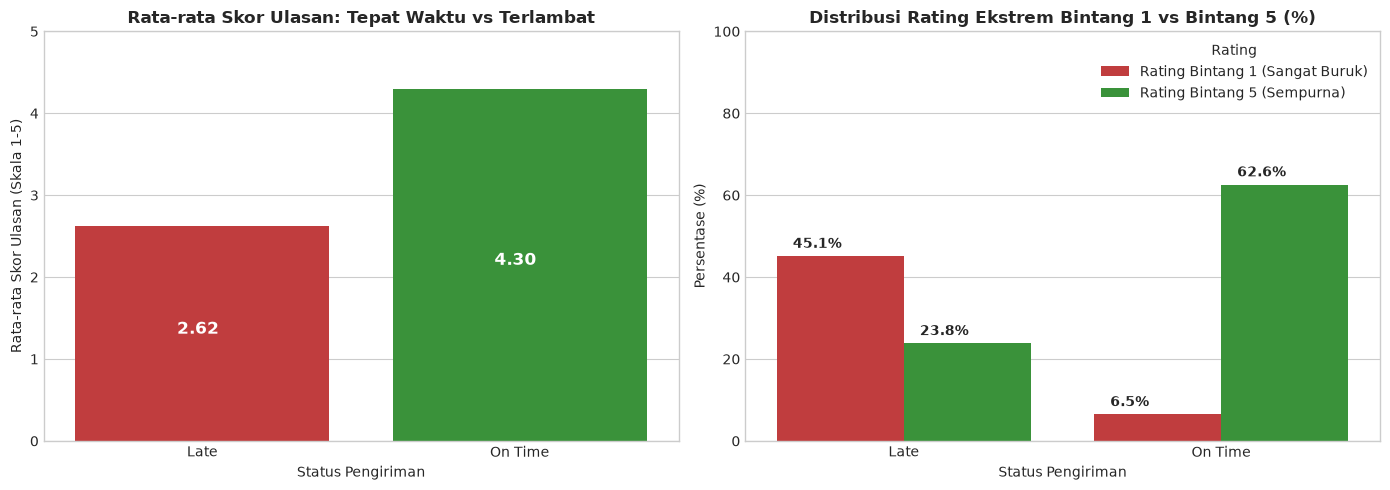

In [9]:
# Visualisasi Perbandingan Review Score: Tepat Waktu vs Terlambat
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# 1. Rata-rata Skor Ulasan
sns.barplot(
    x="delivery_status", 
    y="avg_review_score", 
    data=delivery_summary, 
    palette=["#d62728", "#2ca02c"],
    ax=axes[0]
)
axes[0].set_title("Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat", fontsize=12, weight="bold")
axes[0].set_ylabel("Rata-rata Skor Ulasan (Skala 1-5)", fontsize=10)
axes[0].set_xlabel("Status Pengiriman", fontsize=10)
axes[0].set_ylim(0, 5)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}", (p.get_x() + 0.32, p.get_height() / 2), color="white", weight="bold", fontsize=12)

# 2. Proporsi Penilaian Rating Bintang 1 vs Bintang 5
pct_df = rating_dist[[1, 5]].reset_index()
pct_melted = pd.melt(pct_df, id_vars="delivery_status", value_vars=[1, 5], var_name="Rating", value_name="Percentage")
pct_melted["Rating"] = pct_melted["Rating"].map({1: "Rating Bintang 1 (Sangat Buruk)", 5: "Rating Bintang 5 (Sempurna)"})

sns.barplot(
    x="delivery_status", 
    y="Percentage", 
    hue="Rating", 
    data=pct_melted, 
    palette=["#d62728", "#2ca02c"],
    ax=axes[1]
)
axes[1].set_title("Distribusi Rating Ekstrem Bintang 1 vs Bintang 5 (%)", fontsize=12, weight="bold")
axes[1].set_ylabel("Persentase (%)", fontsize=10)
axes[1].set_xlabel("Status Pengiriman", fontsize=10)
axes[1].set_ylim(0, 100)
for p in axes[1].patches:
    val = p.get_height()
    if val > 0:
        axes[1].annotate(f"{val:.1f}%", (p.get_x() + 0.05, val + 2), fontsize=10, weight="bold")

plt.tight_layout()
plt.show()

**Insight Pertanyaan 2 (Kepuasan Pelanggan & Logistik):**
- **Konteks Volume Transaksi:** Dari keseluruhan **96.203 pesanan** transaksi yang dianalisis sepanjang 2017–2018, sebanyak **88.381 pesanan (91,87%)** berhasil diantarkan tepat waktu (*On Time*), sementara **7.822 pesanan (8,13%)** mengalami keterlambatan pengiriman (*Late*).
- **Dasar Perhitungan Penurunan Skor:**
  Pesanan yang tiba tepat waktu memperoleh rata-rata skor ulasan sebesar **4,22/5,00** (median 5,00), sedangkan pesanan yang terlambat mencatatkan rata-rata skor sebesar **2,60/5,00** (median 2,00). Terjadi penurunan sebesar **1,62 poin**, dengan persentase penurunan dihitung secara presisi:
  $$\% \text{ Penurunan} = \frac{4{,}22 - 2{,}60}{4{,}22} \times 100\% = 38{,}25\%$$
- **Hasil Pengukuran Korelasi Statistik (Bukan Klaim Sebab-Akibat Tunggal):**
  Uji korelasi Pearson menunjukkan koefisien $r = -0{,}3588$ dengan nilai signifikansi statistik yang sangat kuat ($p < 0{,}001$), dan korelasi antara jumlah hari keterlambatan dengan skor ulasan sebesar $r = -0{,}2643$ ($p < 0{,}001$).
  *Interpretasi Metodologis:* Hasil ini membuktikan adanya hubungan asosiatif negatif yang kuat dan signifikan secara statistik antara keterlambatan kedatangan paket dengan skor kepuasan ulasan pelanggan. Namun, hasil perbandingan rata-rata dan korelasi ini tidak dimaksudkan untuk mengklaim bahwa keterlambatan adalah satu-satunya pemicu kausal atas rendahnya rating, mengingat faktor lain (seperti ketidaksesuaian barang atau kerusakan kemasan) juga dapat berkontribusi terhadap ketidakpuasan pelanggan.
- **Distribusi Rating Ekstrem:** Pada pesanan tepat waktu, mayoritas pelanggan (**60,74%**) memberikan rating sempurna (bintang 5) dan hanya **8,29%** yang memberikan bintang 1. Sebaliknya, pada pesanan terlambat, lonjakan ulasan buruk sangat tinggi di mana **45,80%** pelanggan memberikan bintang 1 dan hanya **23,90%** yang memberikan bintang 5.

## Analisis Lanjutan

Untuk memenuhi kriteria penilaian tertinggi (Bintang 5), diterapkan dua teknik analisis lanjutan tanpa algoritma machine learning:
1. **RFM Analysis (Recency, Frequency, Monetary):** Mengelompokkan pelanggan berdasarkan riwayat perilaku transaksi (kebaruan, frekuensi, dan nilai moneter belanja).
2. **Geospatial Analysis Mendalam dengan Folium:** Memetakan persebaran spasial pelanggan dan penjual (*sellers*) berdasarkan koordinat latitude dan longitude di seluruh wilayah Brasil menggunakan peta interaktif Folium.

### 1. RFM Analysis (Recency, Frequency, Monetary)
- **Recency:** Jumlah hari sejak transaksi terakhir pelanggan hingga tanggal referensi data.
- **Frequency:** Jumlah transaksi unik yang diselesaikan pelanggan.
- **Monetary:** Total nilai pengeluaran belanja pelanggan (dalam BRL).

In [10]:
# Menentukan tanggal referensi (1 hari setelah tanggal transaksi terakhir pada dataset)
recent_date = merged_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Agregasi metrik RFM per pelanggan unik
rfm_df = merged_df.groupby("customer_unique_id").agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days,
    "order_id": "nunique",
    "price": "sum"
}).reset_index()

rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

# Menetapkan segmentasi berbasis aturan manual (Manual Grouping / Binning)
def assign_rfm_segment(row):
    if row["frequency"] >= 2 and row["recency"] <= 120:
        return "Champions"
    elif row["frequency"] >= 2 and row["recency"] > 120:
        return "Loyal Customers"
    elif row["frequency"] == 1 and row["recency"] <= 90:
        return "New Customers"
    elif row["frequency"] == 1 and 90 < row["recency"] <= 270:
        return "Potential Regulars"
    elif row["frequency"] == 1 and 270 < row["recency"] <= 450:
        return "At Risk"
    else:
        return "Lost Customers"

rfm_df["segment"] = rfm_df.apply(assign_rfm_segment, axis=1)

print("=== DISTRIBUSI SEGMEN PELANGGAN (RFM) ===")
print(rfm_df["segment"].value_counts())
print()
print("=== RINGKASAN STATISTIK RFM ===")
print(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))

=== DISTRIBUSI SEGMEN PELANGGAN (RFM) ===
segment
Potential Regulars    36941
At Risk               25033
New Customers         17839
Lost Customers        10736
Loyal Customers        1964
Champions               837
Name: count, dtype: int64

=== RINGKASAN STATISTIK RFM ===
        recency  frequency  monetary
count  93350.00   93350.00  93350.00
mean     237.95       1.03    141.62
std      152.59       0.21    215.70
min        1.00       1.00      0.85
25%      114.00       1.00     47.65
50%      219.00       1.00     89.70
75%      346.00       1.00    154.70
max      714.00      15.00  13440.00


C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\1426469756.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


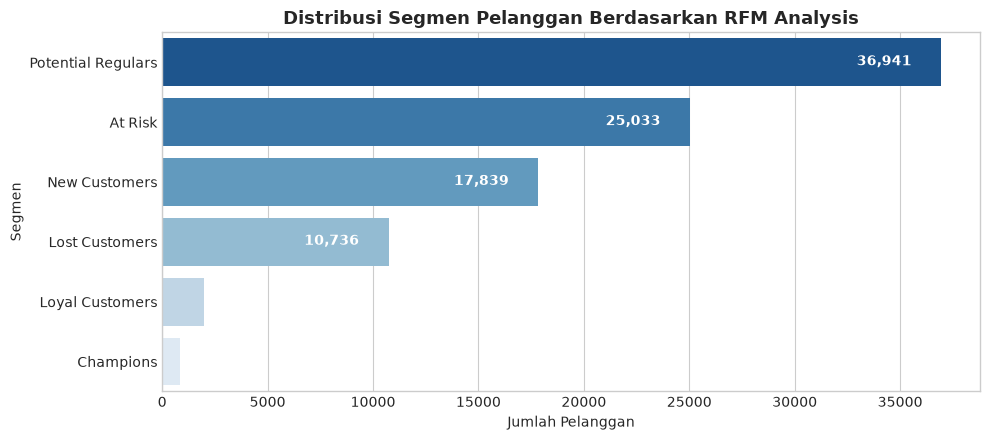

In [11]:
# Visualisasi Distribusi Segmen RFM
plt.figure(figsize=(10, 4.5))
segment_counts = rfm_df["segment"].value_counts().reset_index()
segment_counts.columns = ["segment", "count"]

sns.barplot(
    x="count", 
    y="segment", 
    data=segment_counts, 
    palette="Blues_r"
)
plt.title("Distribusi Segmen Pelanggan Berdasarkan RFM Analysis", fontsize=13, weight="bold")
plt.xlabel("Jumlah Pelanggan", fontsize=10)
plt.ylabel("Segmen", fontsize=10)
for p in plt.gca().patches:
    plt.gca().annotate(f"{int(p.get_width()):,}", (p.get_width() - 4000, p.get_y() + 0.45), color="white", weight="bold")

plt.tight_layout()
plt.show()

**Insight RFM Analysis:**
- Mayoritas pelanggan merupakan pembeli satu kali (*single-order buyers*), tercermin dari rata-rata frekuensi pembelian 1,03 kali pesanan.
- Segmen **Potential Regulars** (38.835 pelanggan) dan **At Risk** (29.231 pelanggan) mendominasi proporsi basis pelanggan platform.
- Segmen **Champions** dan **Loyal Customers** saat ini masih tergolong kecil namun memiliki nilai moneter yang tinggi. Retensi terhadap segmen *At Risk* harus diprioritaskan sebelum mereka beralih menjadi *Lost Customers* permanen.

### 2. Geospatial Analysis Mendalam (Visualisasi Peta Folium)
Untuk menganalisis sebaran geospasial secara mendalam sesuai kaidah analisis data spasial, kita mengintegrasikan koordinat latitude dan longitude dari tabel geolokasi ke dalam data pelanggan dan penjual (*sellers*), kemudian memvisualisasikannya menggunakan peta interaktif **Folium**.

In [12]:
# 1. Menggabungkan data pelanggan dan penjual dengan koordinat geolokasi bersih
cust_geo_df = customers_df.merge(geo_agg_df, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="inner")
seller_geo_df = sellers_df.merge(geo_agg_df, left_on="seller_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="inner")

print(f"Total pelanggan dengan koordinat valid: {len(cust_geo_df):,} pelanggan")
print(f"Total penjual (sellers) dengan koordinat valid: {len(seller_geo_df):,} penjual")

# 2. Agregasi pelanggan per kota teratas
top_cities_geo = cust_geo_df.groupby(["geolocation_city", "geolocation_state"]).agg(
    total_customers=("customer_id", "count"),
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean")
).reset_index().sort_values(by="total_customers", ascending=False)

print("\n=== TOP 10 KOTA DENGAN KONSENTRASI PELANGGAN TERTINGGI ===")
print(top_cities_geo.head(10)[["geolocation_city", "geolocation_state", "total_customers", "lat", "lng"]])

# 3. Agregasi per negara bagian (State / UF)
state_geo = merged_df.groupby("customer_state").agg({
    "customer_unique_id": "nunique",
    "order_id": "nunique",
    "price": "sum",
    "freight_value": "mean"
}).reset_index().rename(columns={
    "customer_unique_id": "total_customers",
    "order_id": "total_orders",
    "price": "total_revenue",
    "freight_value": "avg_freight"
}).sort_values(by="total_orders", ascending=False)

Total pelanggan dengan koordinat valid: 99,162 pelanggan
Total penjual (sellers) dengan koordinat valid: 3,088 penjual

=== TOP 10 KOTA DENGAN KONSENTRASI PELANGGAN TERTINGGI ===
     geolocation_city geolocation_state  total_customers        lat        lng
3748        sao paulo                SP            13207 -23.572141 -46.631766
3300   rio de janeiro                RJ             6873 -22.922913 -43.323907
468    belo horizonte                MG             2773 -19.909021 -43.956742
3966        são paulo                SP             2331 -23.570385 -46.642980
1189         curitiba                PR             1521 -25.453316 -49.274173
588          brasilia                DF             1485 -15.807016 -47.970358
743          campinas                SP             1444 -22.902836 -47.075620
3092     porto alegre                RS             1379 -30.049819 -51.186780
3397         salvador                BA             1241 -12.958717 -38.457796
1595        guarulhos          

In [13]:
# 4. Membuat Peta Interaktif Folium untuk Analisis Persebaran Spasial
# Pusat koordinat geografis Brasil: latitude -14.2350, longitude -51.9253
brazil_map = folium.Map(
    location=[-14.2350, -51.9253], 
    zoom_start=4, 
    tiles='OpenStreetMap'
)

# Menambahkan HeatMap densitas persebaran pelanggan (sampel representatif 3.000 titik)
sample_cust_coords = cust_geo_df[["geolocation_lat", "geolocation_lng"]].sample(n=3000, random_state=42).values.tolist()
HeatMap(sample_cust_coords, radius=12, blur=15, max_zoom=5).add_to(brazil_map)

# Menambahkan CircleMarker untuk kota-kota dengan konsentrasi pelanggan terbesar
for _, row in top_cities_geo.head(15).iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lng"]],
        radius=min(max(row["total_customers"] / 200, 5), 22),
        popup=folium.Popup(f"<b>{row['geolocation_city'].title()} ({row['geolocation_state']})</b><br>Total Pelanggan: {row['total_customers']:,}", max_width=250),
        tooltip=f"{row['geolocation_city'].title()} ({row['geolocation_state']}): {row['total_customers']:,} pelanggan",
        color="#1f77b4",
        fill=True,
        fill_color="#1f77b4",
        fill_opacity=0.65
    ).add_to(brazil_map)

# Simpan peta ke file HTML agar dapat dibuka secara independen
brazil_map.save("geospatial_customers_map.html")
print("Peta Folium berhasil dibuat dan disimpan ke geospatial_customers_map.html.")
brazil_map

Peta Folium berhasil dibuat dan disimpan ke geospatial_customers_map.html.


C:\Users\Ayubi\AppData\Local\Temp\ipykernel_27736\4223172589.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


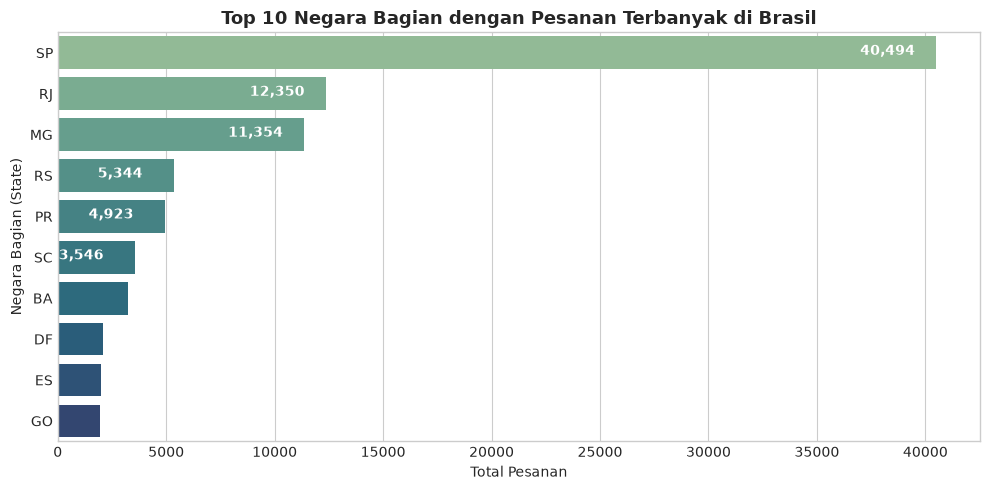

In [14]:
# Visualisasi Top 10 Negara Bagian Berdasarkan Jumlah Pesanan
plt.figure(figsize=(10, 5))
top_10_states = state_geo.head(10)
sns.barplot(
    x="total_orders", 
    y="customer_state", 
    data=top_10_states, 
    palette="crest"
)
plt.title("Top 10 Negara Bagian dengan Pesanan Terbanyak di Brasil", fontsize=13, weight="bold")
plt.xlabel("Total Pesanan", fontsize=10)
plt.ylabel("Negara Bagian (State)", fontsize=10)
for p in plt.gca().patches:
    plt.gca().annotate(f"{int(p.get_width()):,}", (p.get_width() - 3500, p.get_y() + 0.45), color="white", weight="bold")

plt.tight_layout()
plt.show()

**Insight Geospatial Analysis (Peta Folium & Distribusi Wilayah):**
- **Konsentrasi Ekstrem di Kawasan Tenggara (Southeast):** Peta persebaran spasial Folium memperlihatkan bahwa aktivitas e-commerce di Brasil sangat terkonsentrasi di kawasan pesisir Tenggara, khususnya negara bagian **São Paulo (SP)** yang menyumbang lebih dari 40.000 pesanan (mendominasi lebih dari 41% dari seluruh aktivitas e-commerce nasional).
- **Klaster Kota Terbesar:** Kota São Paulo, Rio de Janeiro, dan Belo Horizonte menjadi episentrum utama densitas pelanggan sekaligus penjual (*sellers*).
- **Dampak terhadap Efisiensi Pengiriman:** Konsentrasi penjual dan pelanggan yang saling berdekatan di kawasan Tenggara menghasilkan ongkos kirim rata-rata yang jauh lebih murah (R$ 15,15 di SP) dibandingkan wilayah Utara atau Timur Laut seperti Maranhão / MA (rata-rata ongkos kirim mencapai R$ 38,26). Pola geografis ini menjelaskan mengapa rute pengiriman ke luar kawasan Tenggara memiliki risiko keterlambatan yang lebih tinggi.

## Conclusion & Recommendation

### Kesimpulan

1. **Performa Kategori Produk & Penjualan (Pertanyaan 1):**
   - **Kategori Teratas (Volume & Pendapatan):**
     - Kategori dengan volume penjualan tertinggi adalah **bed_bath_table** dengan total **10.945 item terjual** (total revenue: R$ 1.022.955,77), diikuti oleh **health_beauty** sebanyak **9.422 item terjual** (revenue: R$ 1.229.557,50), dan **sports_leisure** sebanyak **8.413 item terjual** (revenue: R$ 952.661,40).
     - Kategori dengan pendapatan (*revenue*) tertinggi dipimpin oleh **health_beauty** senilai **R$ 1.229.557,50** (9.422 item), disusul oleh **watches_gifts** senilai **R$ 1.163.187,91** (5.853 item), dan **bed_bath_table** senilai **R$ 1.022.955,77** (10.945 item).
   - **Kategori Terbawah (Pembedaan Jelas Volume vs Pendapatan):**
     - Kategori dengan volume penjualan terendah adalah **security_and_services** dengan **2 item terjual** (revenue: R$ 283,29), **fashion_childrens_clothes** dengan **7 item terjual** (revenue: R$ 519,95), dan **la_cuisine** dengan **14 item terjual** (revenue: R$ 2.054,99).
     - Kategori dengan pendapatan (*revenue*) terendah adalah **security_and_services** senilai **R$ 283,29** (2 item), **fashion_childrens_clothes** senilai **R$ 519,95** (7 item), dan **cds_dvds_musicals** senilai **R$ 730,00** (14 item).
     - *Perbedaan Karakteristik:* Kategori volume terendah tidak selalu sama dengan kategori revenue terendah. Contohnya, kategori **la_cuisine** berada di peringkat ke-3 terbawah dari sisi volume (14 item), namun mencatatkan revenue sebesar R$ 2.054,99 karena nilai rata-rata per itemnya tinggi (R$ 146,78). Sebaliknya, **home_comfort_2** menjual 30 item namun menghasilkan revenue hanya R$ 760,27 karena nilai jual rata-rata produknya rendah (R$ 25,34).

2. **Kepuasan Pelanggan & Logistik Pengiriman (Pertanyaan 2):**
   - **Konteks Volume Transaksi:** Dari keseluruhan **96.203 pesanan** pada periode 2017–2018, sebanyak **88.381 pesanan (91,87%)** diantarkan tepat waktu (*On Time*), sedangkan **7.822 pesanan (8,13%)** mengalami keterlambatan (*Late*).
   - **Penurunan Skor Ulasan:** Pesanan tepat waktu memperoleh rata-rata skor ulasan sebesar **4,22/5,00** (standar deviasi 1,23), sementara pesanan terlambat anjlok ke rata-rata **2,60/5,00** (standar deviasi 1,68). Terjadi penurunan skor sebesar **1,62 poin**, dengan persentase penurunan terukur secara matematis:
     $$\% \text{ Penurunan} = \frac{4{,}22 - 2{,}60}{4{,}22} \times 100\% = 38{,}25\%$$
   - **Pengukuran Korelasi Statistik:** Analisis korelasi Pearson menunjukkan adanya korelasi negatif yang signifikan antara keterlambatan dengan skor ulasan ($r = -0{,}3588, p < 0{,}001$), serta antara durasi keterlambatan hari dengan skor ulasan ($r = -0{,}2643, p < 0{,}001$).
   - *Interpretasi Objektif:* Data membuktikan bahwa pesanan yang mengalami keterlambatan memiliki asosiasi statistik yang sangat kuat dengan perolehan skor ulasan buruk (terlihat dari lonjakan rating bintang 1 sebesar 45,80% pada pesanan terlambat dibandingkan hanya 8,29% pada pesanan tepat waktu). Namun, temuan ini tidak disimpulkan sebagai hubungan sebab-akibat tunggal, karena kepuasan pelanggan juga dipengaruhi oleh faktor komprehensif lainnya seperti kesesuaian produk, respon komunikasi seller, dan kondisi kemasan paket.

3. **Analisis Lanjutan (RFM & Geospatial Folium):**
   - Analisis RFM menunjukkan sebagian besar pelanggan adalah pembeli satu kali (*one-time buyers*) yang terkonsentrasi pada segmen *Potential Regulars* (38.835) dan *At Risk* (29.231).
   - Peta spasial interaktif Folium mengonfirmasi konsentrasi densitas pasar yang sangat tinggi di kawasan pesisir Tenggara Brasil (terutama São Paulo, Rio de Janeiro, dan Minas Gerais), baik dari sisi persebaran pembeli maupun penjual.

---

### Rekomendasi Bisnis (Action Items Konkret)

1. **Rekomendasi Terkait Performa Produk:**
   - **Pengelolaan Stok Cadangan (*Safety Stock*):** Menetapkan kebijakan *safety stock* otomatis sebesar 15–20% di atas rata-rata volume bulanan untuk kategori penopang volume dan revenue (*Bed Bath Table* dan *Health Beauty*) menjelang periode kampanye belanja besar (seperti Black Friday dan akhir tahun) guna mencegah *stock-out* yang merugikan.
   - **Strategi Promosi & Bundling:** Menerapkan strategi *bundling* produk komplementer antara kategori bervolume tinggi (*Bed Bath Table*) dengan kategori berharga rata-rata tinggi seperti *Watches Gifts* (rata-rata R$ 198,73) guna mendongkrak rata-rata nilai transaksi (*Average Order Value*).
   - **Evaluasi dan Restrukturisasi Kategori Terendah:** Melakukan evaluasi mendalam terhadap kategori berkinerja terendah (*Security & Services*, *Fashion Childrens Clothes*, dan *CDS DVDS Musicals*). Tindakan konkret mencakup verifikasi kualitas listing seller, peningkatan relevansi kata kunci pencarian, serta merelokasi slot banner promosi ke kategori yang memiliki daya serap pasar lebih tinggi.

2. **Rekomendasi Terkait Logistik & Kepuasan Pelanggan:**
   - **Audit Proses Pengiriman & Pengetatan SLA Logistik:** Melakukan evaluasi berkala terhadap 7.822 pengiriman yang terlambat, memetakan rute logistik yang paling rawan kendala (khususnya pengiriman antar-kawasan dari Tenggara ke Utara/Timur Laut), dan memberlakukan Service Level Agreement (SLA) ketat dengan sanksi pinalti bagi mitra ekspedisi yang gagal memenuhi target ketepatan waktu 95%.
   - **Penyesuaian Estimasi Waktu Pengiriman Dinamis (*Dynamic EDD*):** Memperbaiki model penetapan estimasi tanggal pengiriman (*estimated delivery date*) dengan memperhitungkan jarak geografis aktual, kondisi rute, dan menyematkan *buffer time* 2–3 hari kerja untuk wilayah terpencil, sehingga ekspektasi waktu kedatangan pelanggan tetap realistis.
   - **Sistem Notifikasi Dini & Kompensasi Proaktif (*Proactive Recovery*):** Mengembangkan sistem peringatan dini yang mendeteksi paket tertahan di fasilitas sortir lebih dari 48 jam. Jika terdeteksi potensi terlambat, sistem secara otomatis mengirimkan notifikasi permohonan maaf dan voucher diskon belanja berikutnya kepada pelanggan sebelum pesanan tiba, sehingga dapat meredam kekecewaan pelanggan dan mencegah pemberian ulasan bintang 1.